In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações visuais
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Localização do projeto
ROOT_DIR = Path.cwd()

if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

CAMINHO_DADOS = (
    ROOT_DIR
    / "data"
    / "raw"
    / "sinistros_seguros_sinteticos.csv"
)

df = pd.read_csv(CAMINHO_DADOS)

print(f"Dataset carregado: {df.shape[0]:,} linhas e {df.shape[1]} colunas")
display(df.head())

Dataset carregado: 20,200 linhas e 14 colunas


,id_sinistro,idade_segurado,tempo_cliente_anos,tipo_seguro,regiao,valor_sinistro,valor_apolice,sinistros_anteriores,dias_desde_contratacao,tipo_ocorrencia,canal_aviso,hora_ocorrencia,dias_para_comunicar,fraude_confirmada
0,SIN0000001,23.00,0,Residencial,Nordeste,"5,156.66","22,475.07",0,3005,Colisão,NaN,19,20,0
1,SIN0000002,69.00,18,Empresarial,Nordeste,"2,093.58","12,339.08",1,1901,Dano climático,Site,14,5,0
2,SIN0000003,61.00,5,Automóvel,Norte,"7,778.83","17,468.21",0,2018,Outros,Telefone,15,4,0
3,SIN0000004,47.00,17,Automóvel,Norte,"5,827.49","6,562.18",0,2062,Incêndio,Corretor,3,20,0
4,SIN0000005,47.00,14,Automóvel,Norte,"3,949.73","8,032.87",1,2813,Dano climático,Aplicativo,6,14,0


In [2]:

# 1. Dimensões da base
print("Dimensões:", df.shape)

# 2. Tipos de dados
print("\nTipos de dados:")
display(df.dtypes.to_frame("tipo_de_dado"))

# 3. Valores ausentes
print("\nValores ausentes por coluna:")
ausentes = df.isnull().sum().sort_values(ascending=False)
display(ausentes[ausentes > 0].to_frame("quantidade_ausente"))

# 4. Registros totalmente duplicados
print("\nRegistros totalmente duplicados:", df.duplicated().sum())

# 5. Identificadores duplicados
print("IDs de sinistro duplicados:", df["id_sinistro"].duplicated().sum())

# 6. Distribuição da variável-alvo
print("\nDistribuição da variável fraude_confirmada:")
display(
    df["fraude_confirmada"]
    .value_counts()
    .rename(index={0: "Não fraude", 1: "Fraude"})
    .to_frame("quantidade")
)

print("\nPercentual de fraude:")
display(
    (df["fraude_confirmada"].value_counts(normalize=True) * 100)
    .rename(index={0: "Não fraude", 1: "Fraude"})
    .round(2)
    .to_frame("percentual (%)")
)


Dimensões: (20200, 14)

Tipos de dados:


,tipo_de_dado
id_sinistro,str
idade_segurado,float64
tempo_cliente_anos,int64
tipo_seguro,str
regiao,str
valor_sinistro,float64
valor_apolice,float64
sinistros_anteriores,int64
dias_desde_contratacao,int64
tipo_ocorrencia,str



Valores ausentes por coluna:


,quantidade_ausente
tipo_ocorrencia,609
valor_sinistro,608
idade_segurado,607
canal_aviso,603



Registros totalmente duplicados: 200
IDs de sinistro duplicados: 200

Distribuição da variável fraude_confirmada:


,quantidade
fraude_confirmada,
Não fraude,19291
Fraude,909



Percentual de fraude:


,percentual (%)
fraude_confirmada,
Não fraude,95.50
Fraude,4.50


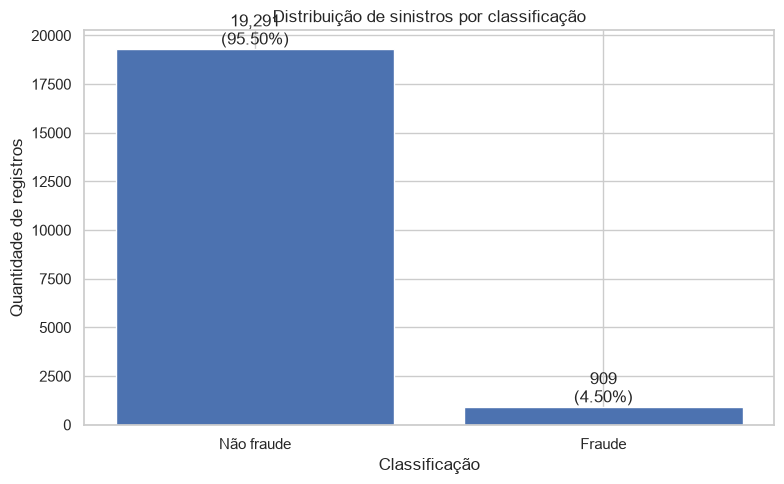

In [3]:

# Contagem e percentual da variável-alvo
contagem = df["fraude_confirmada"].value_counts().sort_index()

rotulos = ["Não fraude", "Fraude"]

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    rotulos,
    [contagem.get(0, 0), contagem.get(1, 0)]
)

ax.set_title("Distribuição de sinistros por classificação")
ax.set_xlabel("Classificação")
ax.set_ylabel("Quantidade de registros")

# Exibir quantidade e percentual sobre as barras
total = len(df)

for barra in barras:
    valor = barra.get_height()
    percentual = valor / total * 100

    ax.annotate(
        f"{int(valor):,}\n({percentual:.2f}%)",
        (barra.get_x() + barra.get_width() / 2, valor),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [4]:

# Selecionar as variáveis numéricas
colunas_numericas = df.select_dtypes(include="number").columns.drop(
    "fraude_confirmada"
)

# Estatísticas descritivas
display(df[colunas_numericas].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
idade_segurado,"19,593.00",50.67,19.46,-5.00,34.00,51.00,67.00,84.00
tempo_cliente_anos,"20,200.00",12.05,7.23,0.00,6.00,12.00,18.00,24.00
valor_sinistro,"19,592.00","8,150.24","11,045.07",-100.00,"2,501.14","4,891.82","9,611.62","322,995.08"
valor_apolice,"20,200.00","10,319.48","8,307.09",532.88,"5,014.85","7,994.08","12,958.46","135,922.86"
sinistros_anteriores,"20,200.00",0.70,0.84,0.00,0.00,1.00,1.00,6.00
dias_desde_contratacao,"20,200.00","1,822.00","1,047.05",1.00,916.75,"1,816.00","2,720.00","3,649.00"
hora_ocorrencia,"20,200.00",11.51,6.93,0.00,5.00,11.50,18.00,23.00
dias_para_comunicar,"20,200.00",14.93,8.92,0.00,7.00,15.00,23.00,30.00


# Principais descobertas
Variável	Evidência	Interpretação
idade_segurado	Mínimo = -5	Valor inválido que precisa ser investigado
valor_sinistro	Mínimo = -100	Valor negativo suspeito para um sinistro
valor_sinistro	Máximo = R$ 322.995,08	Valor extremo que merece investigação, mas não deve ser removido automaticamente
valor_apolice	Máximo = R$ 135.922,86	Também apresenta valores extremos
sinistros_anteriores	Máximo = 6	Pode ser válido; precisamos entender a distribuição
dias_desde_contratacao	Entre 1 e 3.649 dias	Intervalo plausível para o tempo desde a contratação

In [5]:

# Investigar idades inválidas
print("Idades negativas:")
display(df.loc[df["idade_segurado"] < 0, ["id_sinistro", "idade_segurado"]])

print("Idades acima de 100:")
display(df.loc[df["idade_segurado"] > 100, ["id_sinistro", "idade_segurado"]])

# Investigar valores de sinistro inválidos
print("Valores de sinistro negativos:")
display(df.loc[df["valor_sinistro"] < 0, ["id_sinistro", "valor_sinistro"]])

# Investigar valores extremos pelo percentil 99
for coluna in ["valor_sinistro", "valor_apolice"]:
    limite = df[coluna].quantile(0.99)

    print(f"\n{coluna}")
    print(f"Percentil 99: {limite:,.2f}")
    print(f"Registros acima do percentil 99: {(df[coluna] > limite).sum():,}")


Idades negativas:


,id_sinistro,idade_segurado
343,SIN0000344,-5.00
421,SIN0000422,-5.00
1370,SIN0001371,-5.00
2312,SIN0002313,-5.00
2450,SIN0002451,-5.00
2692,SIN0002693,-5.00
3577,SIN0003578,-5.00
3807,SIN0003808,-5.00
4052,SIN0004053,-5.00
4187,SIN0004188,-5.00


Idades acima de 100:


,id_sinistro,idade_segurado


Valores de sinistro negativos:


,id_sinistro,valor_sinistro
738,SIN0000739,-100.00
1408,SIN0001409,-100.00
1429,SIN0001430,-100.00
1587,SIN0001588,-100.00
1697,SIN0001698,-100.00
1850,SIN0001851,-100.00
2312,SIN0002313,-100.00
2776,SIN0002777,-100.00
3759,SIN0003760,-100.00
5320,SIN0005321,-100.00



valor_sinistro
Percentil 99: 52,274.71
Registros acima do percentil 99: 196

valor_apolice
Percentil 99: 41,750.69
Registros acima do percentil 99: 202


# Interpretação dos resultados
Verificação	Resultado	Decisão inicial
Idades negativas	40 registros	Tratar como inválidas
Idades acima de 100	0	Nenhum caso encontrado
Valores de sinistro negativos	40 registros	Tratar como inválidos
Sinistros acima do percentil 99	196 registros	Investigar, não excluir automaticamente
Apólices acima do percentil 99	202 registros	Investigar, não excluir automaticamente

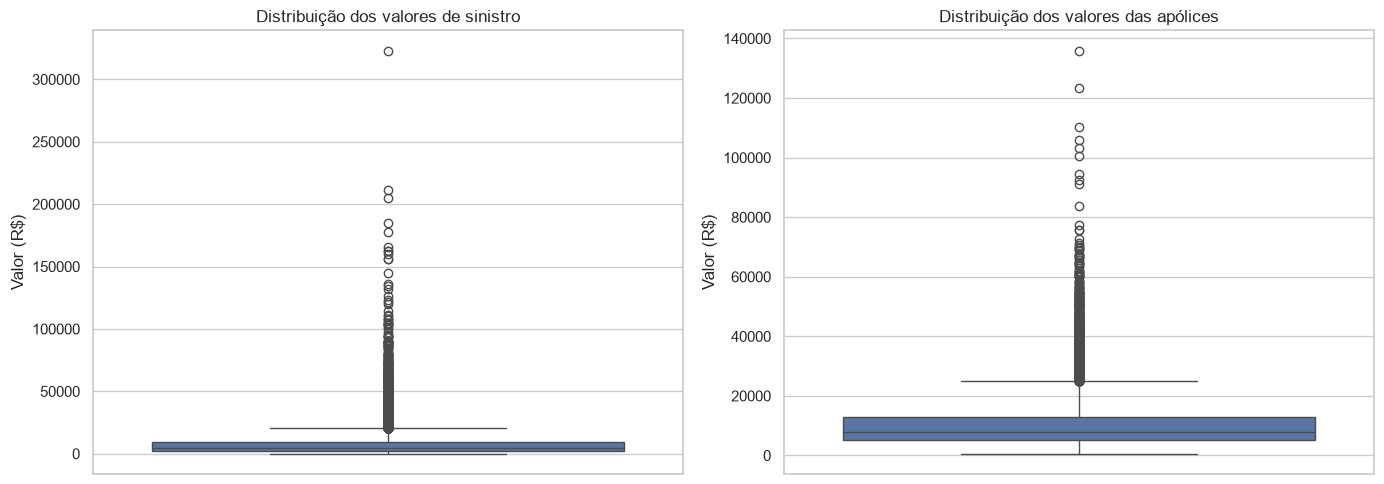

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, y="valor_sinistro", ax=axes[0])
axes[0].set_title("Distribuição dos valores de sinistro")
axes[0].set_ylabel("Valor (R$)")

sns.boxplot(data=df, y="valor_apolice", ax=axes[1])
axes[1].set_title("Distribuição dos valores das apólices")
axes[1].set_ylabel("Valor (R$)")

plt.tight_layout()

fig.savefig(
    "boxplots_valores_financeiros.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [9]:

for coluna in ["valor_sinistro", "valor_apolice"]:
    dados = df[coluna].dropna()

    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    extremos = dados[
        (dados < limite_inferior) |
        (dados > limite_superior)
    ]

    print(f"\nVariável: {coluna}")
    print(f"Q1: {q1:,.2f}")
    print(f"Q3: {q3:,.2f}")
    print(f"Limite inferior: {limite_inferior:,.2f}")
    print(f"Limite superior: {limite_superior:,.2f}")
    print(f"Quantidade de valores extremos: {len(extremos):,}")



Variável: valor_sinistro
Q1: 2,501.14
Q3: 9,611.62
Limite inferior: -8,164.57
Limite superior: 20,277.35
Quantidade de valores extremos: 1,540

Variável: valor_apolice
Q1: 5,014.85
Q3: 12,958.45
Limite inferior: -6,900.56
Limite superior: 24,873.87
Quantidade de valores extremos: 1,109


# O que isso significa para o projeto?
- O método IQR identificou muitos valores extremos, principalmente em valor_sinistro.
- Isso não significa que 1.540 sinistros sejam fraudulentos.
- Em prevenção de fraudes, excluir valores financeiros altos automaticamente pode retirar justamente casos relevantes.
- Vamos preservar a base original e documentar as regras de limpeza antes de treinar os modelos.

In [10]:

colunas_categoricas = [
    "tipo_seguro",
    "regiao",
    "tipo_ocorrencia",
    "canal_aviso",
]

for coluna in colunas_categoricas:
    print(f"\nDistribuição: {coluna}")

    display(
        df[coluna]
        .value_counts(dropna=False)
        .rename_axis(coluna)
        .to_frame("quantidade")
    )



Distribuição: tipo_seguro


,quantidade
tipo_seguro,
Automóvel,12896
Residencial,3092
Vida,2013
Empresarial,1997
automóvel,202



Distribuição: regiao


,quantidade
regiao,
Sudeste,4083
Norte,4054
Nordeste,4049
Sul,4021
Centro-Oeste,3993



Distribuição: tipo_ocorrencia


,quantidade
tipo_ocorrencia,
Dano climático,3986
Outros,3976
Incêndio,3918
Colisão,3913
Roubo,3798
NaN,609



Distribuição: canal_aviso


,quantidade
canal_aviso,
Aplicativo,4957
Site,4942
Telefone,4872
Corretor,4826
NaN,603


# 1. Principais descobertas
Variável	Descoberta	Ação recomendada
tipo_seguro	Automóvel e automóvel aparecem separadamente	Padronizar maiúsculas/minúsculas e espaços
regiao	Cinco regiões com contagens próximas	Investigar a distribuição, sem presumir erro
tipo_ocorrencia	609 valores ausentes	Investigar e tratar posteriormente
canal_aviso	603 valores ausentes	Investigar e tratar posteriormente

In [11]:

colunas_categoricas = [
    "tipo_seguro",
    "regiao",
    "tipo_ocorrencia",
    "canal_aviso",
]

for coluna in colunas_categoricas:
    resumo = (
        df.groupby(coluna, dropna=False)["fraude_confirmada"]
        .agg(
            quantidade="size",
            fraudes="sum",
            taxa_fraude="mean"
        )
        .sort_values("taxa_fraude", ascending=False)
    )

    resumo["taxa_fraude"] = (resumo["taxa_fraude"] * 100).round(2)

    print(f"\nTaxa de fraude por {coluna}:")
    display(resumo)



Taxa de fraude por tipo_seguro:


,quantidade,fraudes,taxa_fraude
tipo_seguro,,,
Automóvel,12896,601,4.66
Vida,2013,88,4.37
Empresarial,1997,84,4.21
Residencial,3092,128,4.14
automóvel,202,8,3.96



Taxa de fraude por regiao:


,quantidade,fraudes,taxa_fraude
regiao,,,
Centro-Oeste,3993,195,4.88
Sul,4021,179,4.45
Sudeste,4083,181,4.43
Nordeste,4049,179,4.42
Norte,4054,175,4.32



Taxa de fraude por tipo_ocorrencia:


,quantidade,fraudes,taxa_fraude
tipo_ocorrencia,,,
Colisão,3913,186,4.75
Roubo,3798,173,4.56
Dano climático,3986,180,4.52
Outros,3976,178,4.48
Incêndio,3918,172,4.39
NaN,609,20,3.28



Taxa de fraude por canal_aviso:


,quantidade,fraudes,taxa_fraude
canal_aviso,,,
NaN,603,31,5.14
Corretor,4826,230,4.77
Telefone,4872,220,4.52
Site,4942,216,4.37
Aplicativo,4957,212,4.28


# Principais achados

Região Centro-Oeste
4,88%
Maior taxa de fraude simulada entre as regiões, contra 4,32% no Norte.




Seguro Automóvel
4,66%
Categoria com maior taxa entre os tipos de seguro após considerar a categoria escrita como Automóvel; precisamos padronizar automóvel.




Canal de aviso ausente
5,14%
É a maior taxa entre os grupos de canal apresentados. Isso é uma pista exploratória, não evidência de que os valores ausentes indiquem fraude.




Ocorrência ausente
3,28%
A taxa é inferior à média geral de 4,50%. Precisamos investigar os dados ausentes sem presumir que sejam aleatórios.

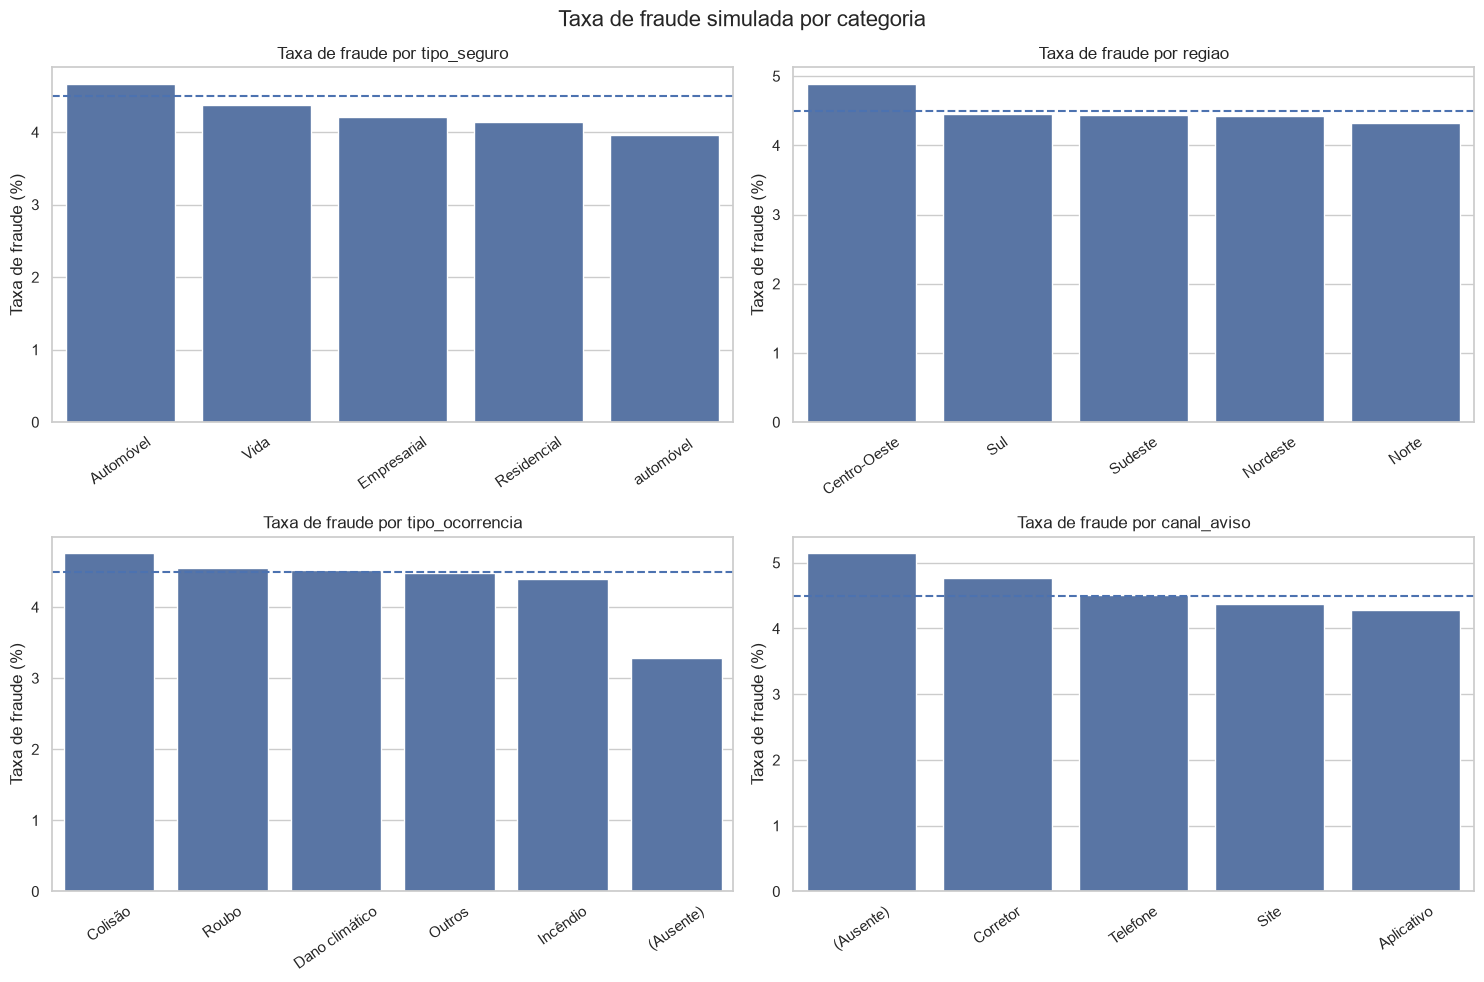

In [12]:

colunas = [
    "tipo_seguro",
    "regiao",
    "tipo_ocorrencia",
    "canal_aviso",
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, coluna in zip(axes, colunas):
    resumo = (
        df.groupby(coluna, dropna=False)["fraude_confirmada"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    rotulos = [
        "(Ausente)" if pd.isna(valor) else str(valor)
        for valor in resumo.index
    ]

    sns.barplot(
        x=rotulos,
        y=resumo.values,
        ax=ax
    )

    ax.set_title(f"Taxa de fraude por {coluna}")
    ax.set_xlabel("")
    ax.set_ylabel("Taxa de fraude (%)")
    ax.tick_params(axis="x", rotation=35)

    ax.axhline(
        df["fraude_confirmada"].mean() * 100,
        linestyle="--"
    )

plt.suptitle(
    "Taxa de fraude simulada por categoria",
    fontsize=16
)
plt.tight_layout()
plt.show()



# Análise Exploratória de Dados (EDA)
## Projeto de Prevenção de Fraudes em Seguros

### 1. Objetivo
Investigar a qualidade, a distribuição e os padrões exploratórios de um dataset sintético de sinistros de seguros, preparando os dados para a etapa de modelagem preditiva.

### 2. Visão geral da base
- Registros carregados: 20.200.
- Variáveis: 14.
- Registros de fraude simulada: 909.
- Proporção de fraude simulada: 4,50%.
- Registros totalmente duplicados: 200.

### 3. Qualidade dos dados
Foram identificados valores ausentes nas variáveis `idade_segurado`, `valor_sinistro`, `tipo_ocorrencia` e `canal_aviso`.

Também foram encontrados 40 registros com idade negativa e 40 registros com valor de sinistro negativo. Esses valores serão investigados e tratados por regras documentadas, preservando a base original.

A variável `tipo_seguro` apresenta diferenças de grafia entre `Automóvel` e `automóvel`, indicando a necessidade de padronização categórica.

### 4. Valores extremos
O método IQR identificou 1.540 valores extremos em `valor_sinistro` e 1.109 em `valor_apolice`.

Essas observações não serão excluídas automaticamente, pois valores financeiros elevados podem ser legítimos e relevantes para a investigação de sinistros suspeitos.

### 5. Análise da variável-alvo
A variável `fraude_confirmada` apresenta desbalanceamento: 4,50% dos registros são classificados como fraude simulada e 95,50% como não fraude.

A avaliação dos modelos deverá considerar métricas como precision, recall, F1-score e PR-AUC, além da acurácia.

### 6. Análise por categorias
As maiores taxas observadas foram:
- Região Centro-Oeste: 4,88%.
- Tipo de seguro Automóvel (grafia original): 4,66%.
- Canal de aviso ausente: 5,14%.

Essas diferenças são exploratórias e não demonstram causalidade. Os resultados refletem, em parte, as regras artificiais usadas na geração da base.

### 7. Limitações
Os dados são sintéticos e não representam sinistros reais. Os padrões encontrados são didáticos e não devem ser interpretados como evidência de comportamento de fraude no mercado segurador.

### 8. Próximas etapas
1. Investigar e remover duplicatas conforme critérios documentados.
2. Tratar inconsistências e valores ausentes.
3. Padronizar categorias.
4. Construir o pipeline de preparação dos dados.
5. Treinar e avaliar modelos com atenção ao desbalanceamento.


In [13]:

# Preservar a base original e criar uma cópia para tratamento
df_tratado = df.copy()

# Diagnóstico de duplicatas
duplicatas_completas = df_tratado.duplicated().sum()
ids_duplicados = df_tratado["id_sinistro"].duplicated().sum()

print("Registros originais:", len(df_tratado))
print("Duplicatas completas:", duplicatas_completas)
print("IDs duplicados:", ids_duplicados)

# Remover somente registros totalmente duplicados
df_tratado = df_tratado.drop_duplicates().copy()

print("\nApós remover duplicatas completas:")
print("Registros:", len(df_tratado))
print("Duplicatas completas restantes:", df_tratado.duplicated().sum())
print(
    "IDs duplicados restantes:",
    df_tratado["id_sinistro"].duplicated().sum()
)


Registros originais: 20200
Duplicatas completas: 200
IDs duplicados: 200

Após remover duplicatas completas:
Registros: 20000
Duplicatas completas restantes: 0
IDs duplicados restantes: 0


# Tratar valores inválidos
Na EDA, identificamos:
- 40 idades negativas;
- 40 valores de sinistro negativos.
Como não sabemos quais seriam os valores verdadeiros, a estratégia inicial será substituir essas observações por valores ausentes (NaN). Depois, vamos imputá-las dentro do pipeline de preparação, evitando inventar valores arbitrariamente.

In [14]:

# Quantificar os valores inválidos antes do tratamento
idades_invalidas = (df_tratado["idade_segurado"] < 0).sum()
sinistros_invalidos = (df_tratado["valor_sinistro"] < 0).sum()

print("Idades negativas:", idades_invalidas)
print("Valores de sinistro negativos:", sinistros_invalidos)

# Substituir valores inválidos por NaN
df_tratado.loc[
    df_tratado["idade_segurado"] < 0,
    "idade_segurado"
] = np.nan

df_tratado.loc[
    df_tratado["valor_sinistro"] < 0,
    "valor_sinistro"
] = np.nan

# Conferir o resultado
print("\nApós o tratamento:")
print(
    "Idades negativas restantes:",
    (df_tratado["idade_segurado"] < 0).sum()
)
print(
    "Valores de sinistro negativos restantes:",
    (df_tratado["valor_sinistro"] < 0).sum()
)

print("\nValores ausentes atualizados:")
display(
    df_tratado.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("quantidade_ausente")
)


Idades negativas: 40
Valores de sinistro negativos: 40

Após o tratamento:
Idades negativas restantes: 0
Valores de sinistro negativos restantes: 0

Valores ausentes atualizados:


,quantidade_ausente
idade_segurado,640
valor_sinistro,640
canal_aviso,600
tipo_ocorrencia,600
id_sinistro,0
tempo_cliente_anos,0
regiao,0
tipo_seguro,0
sinistros_anteriores,0
valor_apolice,0


Importante: os valores ausentes aumentaram porque transformamos os 40 valores inválidos de cada coluna numérica em NaN. Isso é intencional. Ainda não excluímos esses registros.

# Padronizar as categorias
Na EDA, encontramos inconsistência na categoria de seguro: Automóvel e automóvel. Essa diferença pode fazer o modelo interpretar uma mesma categoria como duas distintas.

In [15]:

# Verificar as categorias antes da padronização
print("Categorias de tipo_seguro antes:")
display(df_tratado["tipo_seguro"].value_counts(dropna=False))

# Remover espaços extras e padronizar maiúsculas/minúsculas
df_tratado["tipo_seguro"] = (
    df_tratado["tipo_seguro"]
    .str.strip()
    .str.lower()
)

# Conferir as categorias após a padronização
print("\nCategorias de tipo_seguro após:")
display(df_tratado["tipo_seguro"].value_counts(dropna=False))


Categorias de tipo_seguro antes:


tipo_seguro
Automóvel      12768
Residencial     3062
Vida            1990
Empresarial     1980
automóvel        200
Name: count, dtype: int64


Categorias de tipo_seguro após:


tipo_seguro
automóvel      12968
residencial     3062
vida            1990
empresarial     1980
Name: count, dtype: int64

O que esse código acima fez?
- .str.strip() remove espaços no início e no fim do texto.
- .str.lower() converte as categorias para letras minúsculas.
- value_counts() mostra quantos registros existem em cada categoria.
Por enquanto, estamos padronizando somente tipo_seguro, que sabemos apresentar essa inconsistência. Depois podemos verificar as demais colunas categóricas.

In [16]:

colunas_categoricas = [
    "tipo_seguro",
    "regiao",
    "tipo_ocorrencia",
    "canal_aviso"
]

for coluna in colunas_categoricas:
    print(f"\n--- {coluna} ---")
    display(
        df_tratado[coluna]
        .value_counts(dropna=False)
        .to_frame("quantidade")
    )



--- tipo_seguro ---


,quantidade
tipo_seguro,
automóvel,12968
residencial,3062
vida,1990
empresarial,1980



--- regiao ---


,quantidade
regiao,
Sudeste,4050
Norte,4021
Nordeste,4010
Sul,3977
Centro-Oeste,3942



--- tipo_ocorrencia ---


,quantidade
tipo_ocorrencia,
Dano climático,3943
Outros,3926
Colisão,3894
Incêndio,3888
Roubo,3749
NaN,600



--- canal_aviso ---


,quantidade
canal_aviso,
Aplicativo,4909
Site,4900
Telefone,4822
Corretor,4769
NaN,600


In [17]:

# Identificar as colunas de texto
colunas_texto = df_tratado.select_dtypes(
    include=["object", "str"]
).columns

# Remover espaços extras no início e no fim
for coluna in colunas_texto:
    df_tratado[coluna] = df_tratado[coluna].str.strip()

# Conferir as categorias após a limpeza
for coluna in [
    "tipo_seguro",
    "regiao",
    "tipo_ocorrencia",
    "canal_aviso"
]:
    print(f"\n{coluna}:")
    print(df_tratado[coluna].nunique(), "categorias distintas")
    display(df_tratado[coluna].value_counts(dropna=False))



tipo_seguro:
4 categorias distintas


tipo_seguro
automóvel      12968
residencial     3062
vida            1990
empresarial     1980
Name: count, dtype: int64


regiao:
5 categorias distintas


regiao
Sudeste         4050
Norte           4021
Nordeste        4010
Sul             3977
Centro-Oeste    3942
Name: count, dtype: int64


tipo_ocorrencia:
5 categorias distintas


tipo_ocorrencia
Dano climático    3943
Outros            3926
Colisão           3894
Incêndio          3888
Roubo             3749
NaN                600
Name: count, dtype: int64


canal_aviso:
4 categorias distintas


canal_aviso
Aplicativo    4909
Site          4900
Telefone      4822
Corretor      4769
NaN            600
Name: count, dtype: int64

In [18]:
# Avaliar valores ausentes
# Quantidade e percentual de valores ausentes
resumo_ausentes = pd.DataFrame({
    "quantidade": df_tratado.isna().sum(),
    "percentual": (df_tratado.isna().mean() * 100).round(2)
})

resumo_ausentes = resumo_ausentes[
    resumo_ausentes["quantidade"] > 0
].sort_values("percentual", ascending=False)

display(resumo_ausentes)


,quantidade,percentual
idade_segurado,640,3.20
valor_sinistro,640,3.20
tipo_ocorrencia,600,3.00
canal_aviso,600,3.00


A análise confirmou que os valores ausentes representam entre 3% e 3,2% da base. Como são percentuais relativamente baixos, podemos preservar os registros e tratar os campos ausentes de acordo com o tipo de variável.

# imputar os valores ausentes
Vamos fazer uma primeira versão da base tratada para a análise exploratória. Para a modelagem, depois implementaremos a imputação dentro de um Pipeline do scikit-learn, ajustado apenas com os dados de treino.
A estratégia será:
- Idade: mediana das idades válidas.
- Valor do sinistro: mediana dos valores válidos.
- Tipo de ocorrência: categoria "Não informado".
- Canal de aviso: categoria "Não informado".
A mediana é menos sensível a valores extremos do que a média. Para as categorias, manter "Não informado" evita inventar uma informação sobre o sinistro.

In [19]:

# Guardar as medianas calculadas a partir dos valores válidos
mediana_idade = df_tratado["idade_segurado"].median()
mediana_sinistro = df_tratado["valor_sinistro"].median()

print(f"Mediana da idade: {mediana_idade:.2f}")
print(f"Mediana do valor do sinistro: R$ {mediana_sinistro:,.2f}")

# Imputar as variáveis numéricas
df_tratado["idade_segurado"] = (
    df_tratado["idade_segurado"].fillna(mediana_idade)
)

df_tratado["valor_sinistro"] = (
    df_tratado["valor_sinistro"].fillna(mediana_sinistro)
)

# Imputar as variáveis categóricas
df_tratado["tipo_ocorrencia"] = (
    df_tratado["tipo_ocorrencia"].fillna("Não informado")
)

df_tratado["canal_aviso"] = (
    df_tratado["canal_aviso"].fillna("Não informado")
)

# Validar o resultado
print("\nValores ausentes restantes:")
display(df_tratado.isna().sum().to_frame("quantidade_ausente"))

print("\nDimensões da base tratada:", df_tratado.shape)


Mediana da idade: 51.00
Mediana do valor do sinistro: R$ 4,904.76

Valores ausentes restantes:


,quantidade_ausente
id_sinistro,0
idade_segurado,0
tempo_cliente_anos,0
tipo_seguro,0
regiao,0
valor_sinistro,0
valor_apolice,0
sinistros_anteriores,0
dias_desde_contratacao,0
tipo_ocorrencia,0



Dimensões da base tratada: (20000, 14)


In [20]:

# 1. Dimensões da base
print("Dimensões:", df_tratado.shape)

# 2. Duplicatas completas e IDs repetidos
print("Duplicatas completas:", df_tratado.duplicated().sum())
print("IDs duplicados:", df_tratado["id_sinistro"].duplicated().sum())

# 3. Valores inválidos
print("Idades negativas:", (df_tratado["idade_segurado"] < 0).sum())
print("Valores de sinistro negativos:", (df_tratado["valor_sinistro"] < 0).sum())

# 4. Verificar a variável-alvo
print("\nDistribuição da variável-alvo:")
display(
    df_tratado["fraude_confirmada"]
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

print("\nProporção da variável-alvo (%):")
display(
    (df_tratado["fraude_confirmada"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
    .to_frame("percentual")
)

# 5. Conferir os tipos de dados
print("\nTipos de dados:")
display(df_tratado.dtypes.to_frame("tipo"))


Dimensões: (20000, 14)
Duplicatas completas: 0
IDs duplicados: 0
Idades negativas: 0
Valores de sinistro negativos: 0

Distribuição da variável-alvo:


,quantidade
fraude_confirmada,
0,19097
1,903



Proporção da variável-alvo (%):


,percentual
fraude_confirmada,
0,95.48
1,4.52



Tipos de dados:


,tipo
id_sinistro,str
idade_segurado,float64
tempo_cliente_anos,int64
tipo_seguro,str
regiao,str
valor_sinistro,float64
valor_apolice,float64
sinistros_anteriores,int64
dias_desde_contratacao,int64
tipo_ocorrencia,str


# Savar a base tratada

In [21]:

# Criar a pasta de destino, se necessário
pasta_processados = ROOT_DIR / "data" / "processed"
pasta_processados.mkdir(parents=True, exist_ok=True)

# Salvar a base tratada sem o índice do pandas
caminho_saida = pasta_processados / "sinistros_seguros_tratados.csv"
df_tratado.to_csv(caminho_saida, index=False, encoding="utf-8-sig")

# Confirmar a gravação
print("Arquivo salvo em:")
print(caminho_saida)
print("\nTamanho da base salva:", df_tratado.shape)
print("Arquivo existe:", caminho_saida.exists())


Arquivo salvo em:
C:\Users\vanio\Documents\MEUS_PROJETOS\prevencao_fraude_seguro\data\processed\sinistros_seguros_tratados.csv

Tamanho da base salva: (20000, 14)
Arquivo existe: True
